<a href="https://colab.research.google.com/github/mysteryea7107/Comparative-Evaluation-of-OLS-Ridge-Lasso-Elastic-Net-and-PLS_for-Baseball-Player-Salary-Prediction/blob/main/Notebooks/Comparative_Evaluation_of_OLS%2C_Ridge%2C_Lasso%2C_Elastic_Net%2C_and_PLS_for_Baseball_Player_Salary_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import root_mean_squared_error, r2_score
import seaborn as sns
from scipy import stats
# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define the file path
file_path = '/content/drive/MyDrive/PUP Grad Data Science/1st Sem/STAT 516 Predictive Modelling Using R Software and Python Application /Baseball/Hitters.csv'




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
### EDA
df = pd.read_csv(file_path)

df.head()

,Unnamed: 0,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,...,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,-Andy Allanson,293,66,1,30,29,14,1,293,66,...,30,29,14,A,E,446,33,20,NaN,A
1,-Alan Ashby,315,81,7,24,38,39,14,3449,835,...,321,414,375,N,W,632,43,10,475.0,N
2,-Alvin Davis,479,130,18,66,72,76,3,1624,457,...,224,266,263,A,W,880,82,14,480.0,A
3,-Andre Dawson,496,141,20,65,78,37,11,5628,1575,...,828,838,354,N,E,200,11,3,500.0,N
4,-Andres Galarraga,321,87,10,39,42,30,2,396,101,...,48,46,33,N,E,805,40,4,91.5,N


In [20]:
print('Shape of the data:{}'.format(df.shape))

Shape of the data:(322, 21)


In [25]:
#Remove observations with missing target variable (Salary)
df = df.dropna(subset=['Salary']).reset_index(drop=True)



In [27]:
df = df.replace('?', np.nan).dropna()
print('Shape of the data:{}'.format(df.shape))

Shape of the data:(263, 21)


In [36]:
print('Check data types)\n{}\n'.format(df.dtypes))

Check data types)
Unnamed: 0     object
AtBat           int64
Hits            int64
HmRun           int64
Runs            int64
RBI             int64
Walks           int64
Years           int64
CAtBat          int64
CHits           int64
CHmRun          int64
CRuns           int64
CRBI            int64
CWalks          int64
League         object
Division       object
PutOuts         int64
Assists         int64
Errors          int64
Salary        float64
NewLeague      object
dtype: object



In [42]:
df.select_dtypes(include=[np.number]).corr()

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors,Salary
AtBat,1.000000,0.963969,0.555102,0.899829,0.796015,0.624448,0.012725,0.207166,0.225341,0.212422,0.237278,0.221393,0.132926,0.309607,0.342117,0.325577,0.394771
Hits,0.963969,1.000000,0.530627,0.910630,0.788478,0.587311,0.018598,0.206678,0.235606,0.189364,0.238896,0.219384,0.122971,0.299688,0.303975,0.279876,0.438675
HmRun,0.555102,0.530627,1.000000,0.631076,0.849107,0.440454,0.113488,0.217464,0.217496,0.492526,0.258347,0.349858,0.227183,0.250931,-0.161602,-0.009743,0.343028
Runs,0.899829,0.910630,0.631076,1.000000,0.778692,0.697015,-0.011975,0.171811,0.191327,0.229701,0.237831,0.202335,0.163700,0.271160,0.179258,0.192609,0.419859
RBI,0.796015,0.788478,0.849107,0.778692,1.000000,0.569505,0.129668,0.278126,0.292137,0.442190,0.307226,0.387777,0.233619,0.312065,0.062902,0.150155,0.449457
Walks,0.624448,0.587311,0.440454,0.697015,0.569505,1.000000,0.134793,0.269450,0.270795,0.349582,0.332977,0.312697,0.429140,0.280855,0.102523,0.081937,0.443867
Years,0.012725,0.018598,0.113488,-0.011975,0.129668,0.134793,1.000000,0.915681,0.897844,0.722371,0.876649,0.863809,0.837524,-0.020019,-0.085118,-0.156512,0.400657
CAtBat,0.207166,0.206678,0.217464,0.171811,0.278126,0.269450,0.915681,1.000000,0.995057,0.801676,0.982747,0.950730,0.906712,0.053393,-0.007897,-0.070478,0.526135
CHits,0.225341,0.235606,0.217496,0.191327,0.292137,0.270795,0.897844,0.995057,1.000000,0.786652,0.984542,0.946797,0.890718,0.067348,-0.013144,-0.068036,0.548910
CHmRun,0.212422,0.189364,0.492526,0.229701,0.442190,0.349582,0.722371,0.801676,0.786652,1.000000,0.825625,0.927903,0.810878,0.093822,-0.188886,-0.165369,0.524931


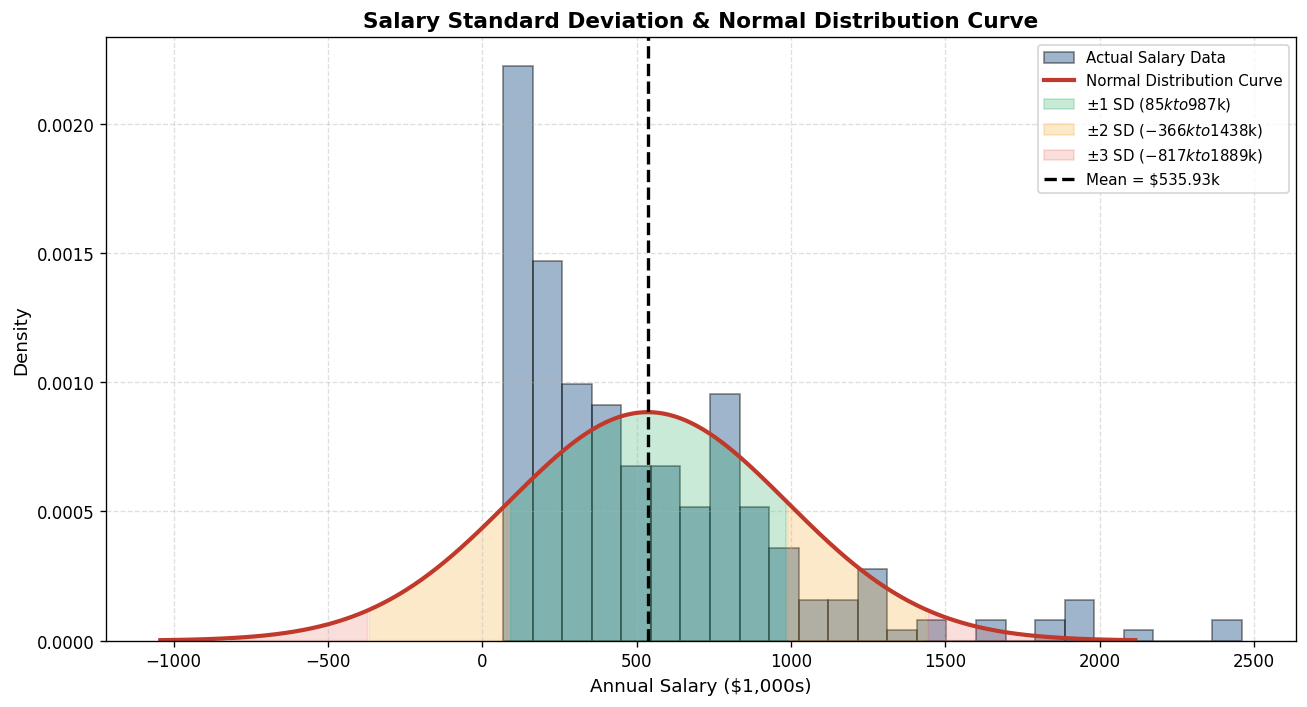

Total Players (with Salary) : 263
Mean Salary (μ)             : $535.93k
Standard Deviation (σ)      : $451.12k
Minimum Salary              : $67.50k
Maximum Salary              : $2460.00k


In [45]:
# 3. Define salary and calculate Mean and Standard Deviation
salary = df["Salary"]
mean_sal = salary.mean()
std_sal = salary.std()

# 4. Build the Standard Deviation Bell Curve Plot
plt.figure(figsize=(11, 6), dpi=120)

# Plot actual Salary histogram (as probability density)
plt.hist(
    salary, bins=25, density=True, color="#2b5c8f", alpha=0.45,
    edgecolor="black", label="Actual Salary Data"
)

# Create theoretical Normal Bell Curve using Salary's Mean & SD
x = np.linspace(mean_sal - 3.5 * std_sal, mean_sal + 3.5 * std_sal, 500)
y = stats.norm.pdf(x, mean_sal, std_sal)
plt.plot(x, y, color="#c0392b", linewidth=2.5, label="Normal Distribution Curve")

# Shade +/- 1 SD, +/- 2 SD, and +/- 3 SD bands
plt.fill_between(
    x, y, where=(np.abs(x - mean_sal) <= std_sal),
    color="#27ae60", alpha=0.25, label=f"±1 SD (${mean_sal - std_sal:.0f}k to ${mean_sal + std_sal:.0f}k)"
)
plt.fill_between(
    x, y, where=((np.abs(x - mean_sal) > std_sal) & (np.abs(x - mean_sal) <= 2 * std_sal)),
    color="#f39c12", alpha=0.22, label=f"±2 SD (${mean_sal - 2*std_sal:.0f}k to ${mean_sal + 2*std_sal:.0f}k)"
)
plt.fill_between(
    x, y, where=((np.abs(x - mean_sal) > 2 * std_sal) & (np.abs(x - mean_sal) <= 3 * std_sal)),
    color="#e74c3c", alpha=0.18, label=f"±3 SD (${mean_sal - 3*std_sal:.0f}k to ${mean_sal + 3*std_sal:.0f}k)"
)

# Plot vertical line for the Mean
plt.axvline(mean_sal, color="black", linestyle="--", linewidth=2, label=f"Mean = ${mean_sal:.2f}k")

# Formatting and labels
plt.title("Salary Standard Deviation & Normal Distribution Curve", fontsize=13, fontweight="bold")
plt.xlabel("Annual Salary ($1,000s)", fontsize=11)
plt.ylabel("Density", fontsize=11)
plt.legend(loc="upper right", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 5. Print Summary Statistics
print(f"Total Players (with Salary) : {len(salary)}")
print(f"Mean Salary (μ)             : ${mean_sal:.2f}k")
print(f"Standard Deviation (σ)      : ${std_sal:.2f}k")
print(f"Minimum Salary              : ${salary.min():.2f}k")
print(f"Maximum Salary              : ${salary.max():.2f}k")

In [49]:
##Normalize Salary using Natural Log Transformation
log_salary = np.log(salary)

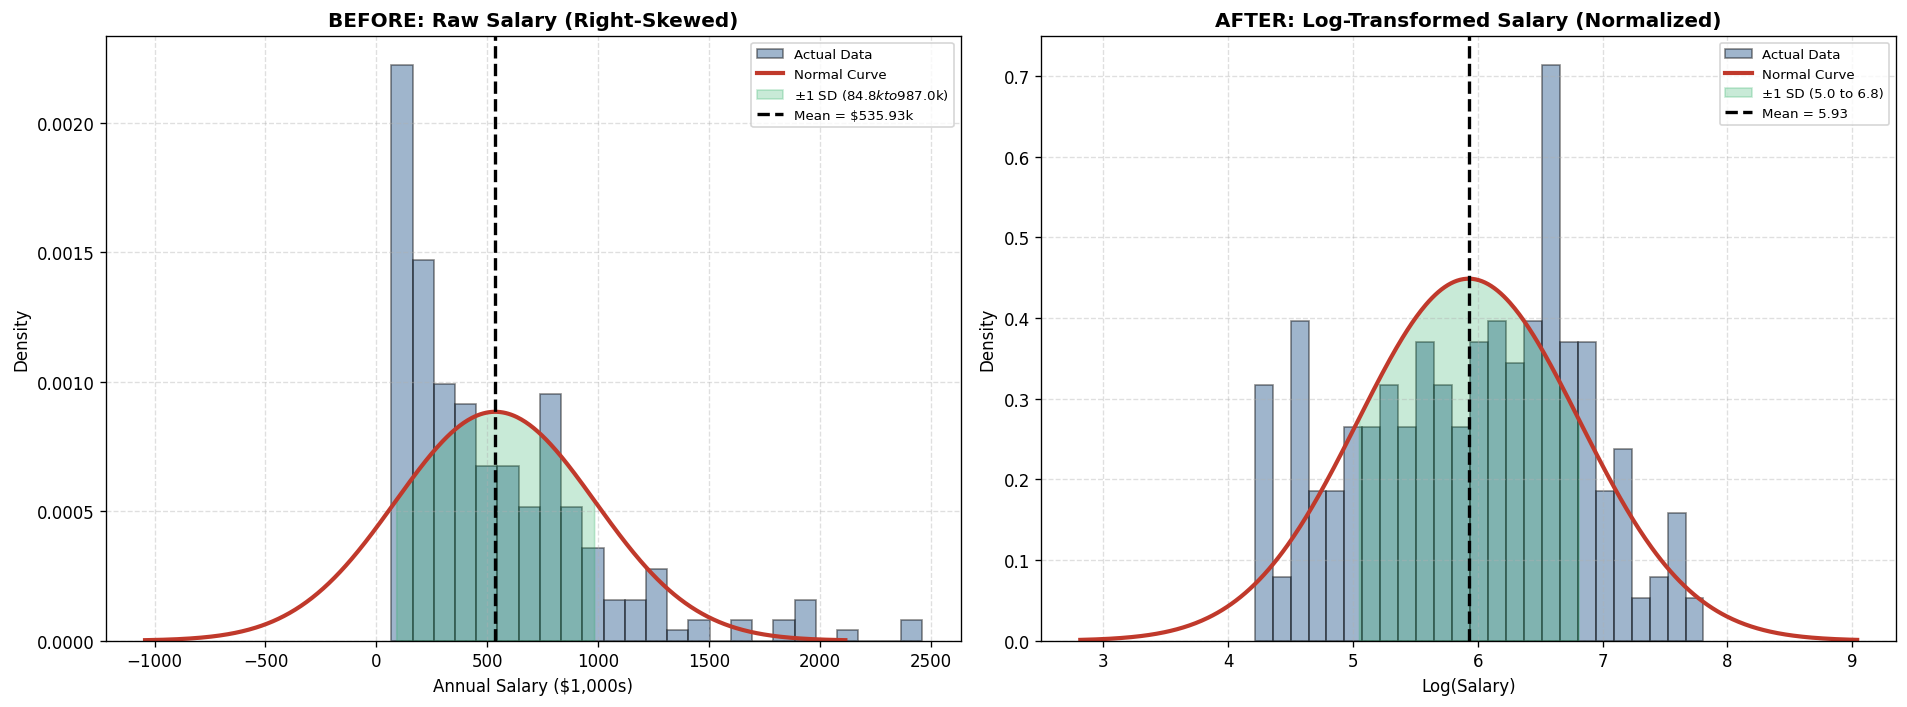

NORMALITY COMPARISON SUMMARY
Raw Salary Skewness : 1.580 | Shapiro p-value: 3.3074e-15
Log Salary Skewness : -0.181 | Shapiro p-value: 0.0000


In [51]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Map the active variable name
raw_salary = salary

# Define the missing helper function to plot the histograms and normal curve overlays
def plot_normal_curve(ax, data, title, xlabel, unit_prefix="", unit_suffix=""):
    mean_val = data.mean()
    std_val = data.std()

    # Plot histogram density
    ax.hist(data, bins=25, density=True, color="#2b5c8f", alpha=0.45, edgecolor="black", label="Actual Data")

    # Generate theoretical Normal Bell Curve
    x_vals = np.linspace(mean_val - 3.5 * std_val, mean_val + 3.5 * std_val, 500)
    y_vals = stats.norm.pdf(x_vals, mean_val, std_val)
    ax.plot(x_vals, y_vals, color="#c0392b", linewidth=2.5, label="Normal Curve")

    # Fill standard deviation bands
    ax.fill_between(x_vals, y_vals, where=(np.abs(x_vals - mean_val) <= std_val),
                    color="#27ae60", alpha=0.25, label=f"±1 SD ({unit_prefix}{mean_val - std_val:.1f}{unit_suffix} to {unit_prefix}{mean_val + std_val:.1f}{unit_suffix})")

    # Add Mean vertical line and formatting
    ax.axvline(mean_val, color="black", linestyle="--", linewidth=2, label=f"Mean = {unit_prefix}{mean_val:.2f}{unit_suffix}")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel("Density", fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, linestyle="--", alpha=0.4)

# Create Side-by-Side Comparison Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=120)

# Left: Original Skewed Salary
plot_normal_curve(
    axes[0], raw_salary,
    title="BEFORE: Raw Salary (Right-Skewed)",
    xlabel="Annual Salary ($1,000s)",
    unit_prefix="$", unit_suffix="k"
)

# Right: Log-Normalized Salary
plot_normal_curve(
    axes[1], log_salary,
    title="AFTER: Log-Transformed Salary (Normalized)",
    xlabel="Log(Salary)",
    unit_prefix="", unit_suffix=""
)

plt.tight_layout()
plt.show()

# Print Normality Test Comparison (Shapiro-Wilk Test)
_, p_raw = stats.shapiro(raw_salary)
_, p_log = stats.shapiro(log_salary)

print("=" * 55)
print("NORMALITY COMPARISON SUMMARY")
print("=" * 55)
print(f"Raw Salary Skewness : {stats.skew(raw_salary):.3f} | Shapiro p-value: {p_raw:.4e}")
print(f"Log Salary Skewness : {stats.skew(log_salary):.3f} | Shapiro p-value: {p_log:.4f}")
print("=" * 55)

In [53]:
# ==============================================================================
# BLOCK: DATA PREPARATION & LOG-NORMALIZED TRAIN/TEST SPLIT
# Report Alignment: Supports Section c (Data Preparation) & Section d (Setup)
# ==============================================================================

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import root_mean_squared_error, r2_score

# Silence solver convergence notices during hyperparameter grid search
warnings.filterwarnings("ignore")

# 1. Remove missing Salary records (reduces 322 players to 263 complete cases)
clean_df = df.dropna(subset=["Salary"]).reset_index(drop=True)

# 2. Separate predictor features (X) and log-normalized target variable (y_log)
X = clean_df.drop(columns=["Salary"])
y_raw = clean_df["Salary"]
y_log = np.log(y_raw)

# 3. Convert categorical text columns (League, Division, NewLeague) into binary 0/1 columns
X_encoded = pd.get_dummies(X, drop_first=True)

# 4. Split into 80% Training Set and 20% Holdout Test Set using a fixed seed (516)
RANDOM_STATE = 516
X_train, X_test, y_train_log, y_test_log, y_train_raw, y_test_raw = train_test_split(
    X_encoded, y_log, y_raw, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Training Samples : {X_train.shape[0]} players | Features: {X_train.shape[1]}")
print(f"Testing Samples  : {X_test.shape[0]} players | Features: {X_test.shape[1]}")

Training Samples : 210 players | Features: 281
Testing Samples  : 53 players | Features: 281


In [ ]:
# ==============================================================================
# BLOCK: MODEL TRAINING & 10-FOLD CROSS-VALIDATION TUNING
# Report Alignment: Section d (Five Methods) & Section e (Tuning Procedure)
# ==============================================================================

# Define a reproducible 10-fold cross-validation splitter
cv_10 = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

# Define 200 candidate regularization penalties (lambda) on a logarithmic scale
lambda_grid = np.logspace(-3, 3, 200)

# --- 1. Ordinary Least Squares (OLS) ---
# Unregularized baseline linear regression (no hyperparameters to tune)
ols_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
ols_pipe.fit(X_train, y_train_log)

# --- 2. Partial Least Squares (PLS) ---
# Tunes the optimal number of latent components (1 to 19) via 10-fold CV
pls_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", PLSRegression())
])
pls_tuner = GridSearchCV(
    estimator=pls_pipe,
    param_grid={"model__n_components": range(1, X_train.shape[1] + 1)},
    cv=cv_10,
    scoring="neg_root_mean_squared_error"
)
pls_tuner.fit(X_train, y_train_log)

# --- 3. Ridge Regression (L2 Penalty) ---
# Shrinks all coefficients smoothly toward zero; tunes optimal lambda via 10-fold CV
ridge_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RidgeCV(alphas=lambda_grid, cv=cv_10))
])
ridge_pipe.fit(X_train, y_train_log)

# --- 4. Lasso Regression (L1 Penalty) ---
# Shrinks weak coefficients to exact zero (feature selection); tunes lambda via 10-fold CV
lasso_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LassoCV(alphas=lambda_grid, cv=cv_10, max_iter=10000, random_state=RANDOM_STATE))
])
lasso_pipe.fit(X_train, y_train_log)

# --- 5. Elastic Net (Combined L1 + L2 Penalties) ---
# Tunes both the L1/L2 mixing ratio (0.1 to 0.9) and overall lambda via 10-fold CV
enet_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNetCV(
        l1_ratio=np.arange(0.1, 1.0, 0.1),
        alphas=lambda_grid,
        cv=cv_10,
        max_iter=10000,
        random_state=RANDOM_STATE
    ))
])
enet_pipe.fit(X_train, y_train_log)

# Print Selected Hyperparameters for Report Section e
print("=" * 60)
print("SECTION e: SELECTED 10-FOLD CV TUNING SETTINGS")
print("=" * 60)
print(f"OLS                  : None (Unregularized Baseline)")
print(f"PLS Optimal Comps    : {pls_tuner.best_params_['model__n_components']} components")
print(f"Ridge Best Lambda    : {ridge_pipe.named_steps['model'].alpha_:.4f}")
print(f"Lasso Best Lambda    : {lasso_pipe.named_steps['model'].alpha_:.4f}")
print(f"Elastic Net Settings : l1_ratio = {enet_pipe.named_steps['model'].l1_ratio_:.2f} | "
      f"Lambda = {enet_pipe.named_steps['model'].alpha_:.4f}")
print("=" * 60)